PLEASE REFER TO APPENDIX ON HOW TO RUN THE CODE, CHANGE THE FILE NAMES ACCORDINGLY IN ORDER FOR THE DATASETS TO BE IMPORTED ON YOUR SYSTEM. YOU CAN LOCATE THE WHEREABOUTS OF THE CSV'S BY CHECKING THE PATHWAY WHERE THE CODE IS TRYING TO IMPORT


USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [1418]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from rapidfuzz import process, fuzz
import pandas as pd
import unidecode
import re

In [1419]:
player_stats_df= pd.read_csv('Data/understat_fifa_merged.csv')

In [1420]:
def nan_analysis(df):
    """
    This function takes a DataFrame and returns a DataFrame with the percentage of NaN values for each column.
    Only columns with NaN values are included in the output DataFrame.
    """
    nan_percentage = df.isna().mean() * 100
    nan_percentage = nan_percentage[nan_percentage > 0].reset_index()
    nan_percentage.columns = ['Column Name', 'Percentage of NaN Values']
    nan_percentage = nan_percentage.sort_values(by='Percentage of NaN Values', ascending=False)
    return nan_percentage

In [1421]:
nan_analysis(player_stats_df)

,Column Name,Percentage of NaN Values
8,Marking,25.000256
16,Composure,13.580045
21,Stamina,2.976294
24,Sprint Speed,2.976294
39,GK Reflexes,2.969132
38,GK Kicking,2.969132
25,Agility,2.969132
26,Jumping,2.969132
27,Heading,2.969132
28,Shot Power,2.969132


In [1422]:
player_stats_df.drop(columns=['Marking', "Composure"], inplace=True)

In [1423]:
player_stats_df[player_stats_df.isna().any(axis=1)]

,Understat_Roster_ID,goals,own_goals,shots,xG,time,Understat_Player_ID_x,Understat_Team_ID,Understat_Position,Understat_Player_Name,...,Penalties,Volleys,GK Positioning,GK Diving,GK Handling,GK Kicking,GK Reflexes,Player URL_y,Player ID,Season
41,548645,0,0,0,0.000000,36,957,73,Sub,yann kermorgant,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
56,57164,0,0,0,0.000000,90,600,72,GK,tim howard,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
78,57186,1,0,2,0.108652,61,1016,90,ML,miguel layun,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
95,57204,0,0,0,0.000000,12,974,75,Sub,yohan benalouane,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
104,57212,0,0,1,0.012197,90,929,77,MR,adam johnson,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97705,663013,0,0,0,0.000000,15,11926,81,Sub,edson alvarez,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
97713,663117,0,0,2,0.118732,90,11839,238,MC,gustavo hamer,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
97716,663120,0,0,2,0.390532,75,11815,238,FW,ben brereton diaz,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
97726,663130,0,0,0,0.000000,90,9105,82,DC,radu dragusin,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


We can manually input this value. Let's check Josh Sims from Southampton version fifa19

In [1424]:
# Define values
player_name = "Josh Sims"
team_name = "Southampton"
version = "fifa19"
stamina = 66
sprint = 80

# Check before update
print("Before:")
print(player_stats_df.loc[
    (player_stats_df['Player Name'] == player_name) &
    (player_stats_df['Team Name'] == team_name) &
    (player_stats_df['Version'] == version),
    ['Stamina', 'Sprint Speed']
])

# Perform update
player_stats_df.loc[
    (player_stats_df['Player Name'] == player_name) &
    (player_stats_df['Team Name'] == team_name) &
    (player_stats_df['Version'] == version),
    ['Stamina', 'Sprint Speed']
] = [stamina, sprint]

# Confirm update
print("After:")
print(player_stats_df.loc[
    (player_stats_df['Player Name'] == player_name) &
    (player_stats_df['Team Name'] == team_name) &
    (player_stats_df['Version'] == version),
    ['Stamina', 'Sprint Speed']
])



Before:
       Stamina  Sprint Speed
40138      NaN           NaN
40694      NaN           NaN
40962      NaN           NaN
41183      NaN           NaN
41589      NaN           NaN
41730      NaN           NaN
42448      NaN           NaN
After:
       Stamina  Sprint Speed
40138     66.0          80.0
40694     66.0          80.0
40962     66.0          80.0
41183     66.0          80.0
41589     66.0          80.0
41730     66.0          80.0
42448     66.0          80.0


In [1425]:
player_stats_df.columns

Index(['Understat_Roster_ID', 'goals', 'own_goals', 'shots', 'xG', 'time',
       'Understat_Player_ID_x', 'Understat_Team_ID', 'Understat_Position',
       'Understat_Player_Name', 'h_a', 'yellow_card', 'red_card', 'roster_in',
       'roster_out', 'key_passes', 'assists', 'xA', 'xGChain', 'xGBuildup',
       'positionOrder', 'Understat_Match_Link', 'Best_Match_Name',
       'Match_Score', 'Understat_Match_ID', 'id', 'season',
       'Understat_Player_ID_y', 'Fifa_Name', 'Player URL_x', 'Player Name',
       'Team Name', 'Version', 'Ball Control', 'Dribbling', 'Slide Tackle',
       'Stand Tackle', 'Aggression', 'Reactions', 'Att. Position',
       'Interceptions', 'Vision', 'Crossing', 'Short Pass', 'Long Pass',
       'Acceleration', 'Stamina', 'Strength', 'Balance', 'Sprint Speed',
       'Agility', 'Jumping', 'Heading', 'Shot Power', 'Finishing',
       'Long Shots', 'Curve', 'FK Acc.', 'Penalties', 'Volleys',
       'GK Positioning', 'GK Diving', 'GK Handling', 'GK Kicking',
    

In [1426]:
nan_analysis(player_stats_df)

,Column Name,Percentage of NaN Values
20,Strength,2.969132
21,Balance,2.969132
23,Agility,2.969132
24,Jumping,2.969132
25,Heading,2.969132
26,Shot Power,2.969132
27,Finishing,2.969132
28,Long Shots,2.969132
29,Curve,2.969132
30,FK Acc.,2.969132


In [1427]:
player_stats_df[(player_stats_df['Understat_Position'] == 'GK') & (player_stats_df['GK Diving'].isna())]

,Understat_Roster_ID,goals,own_goals,shots,xG,time,Understat_Player_ID_x,Understat_Team_ID,Understat_Position,Understat_Player_Name,...,Penalties,Volleys,GK Positioning,GK Diving,GK Handling,GK Kicking,GK Reflexes,Player URL_y,Player ID,Season
56,57164,0,0,0,0.0,90,600,72,GK,tim howard,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
317,57482,0,0,0,0.0,90,600,72,GK,tim howard,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
747,62584,0,0,0,0.0,90,600,72,GK,tim howard,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1036,63806,0,0,0,0.0,90,600,72,GK,tim howard,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1107,63875,0,0,0,0.0,90,600,72,GK,tim howard,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97249,660869,0,0,0,0.0,90,6903,249,GK,matz sels,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
97264,660884,0,0,0,0.0,90,12032,80,GK,djordje petrovic,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
97384,662160,0,0,0,0.0,90,12032,80,GK,djordje petrovic,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
97538,663159,0,0,0,0.0,90,6903,249,GK,matz sels,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [1428]:
non_gk_stats=   [ 'Ball Control', 'Dribbling', 'Slide Tackle',
       'Stand Tackle', 'Aggression', 'Reactions', 'Att. Position',
       'Interceptions', 'Vision', 'Crossing', 'Short Pass', 'Long Pass',
       'Acceleration', 'Stamina', 'Strength', 'Balance', 'Sprint Speed',
       'Agility', 'Jumping', 'Heading', 'Shot Power', 'Finishing',
       'Long Shots', 'Curve', 'FK Acc.', 'Penalties', 'Volleys']

#Fill NaN values of non-gk players with average of the column for each team ('Understat_Team_ID') for each game ('id'), round to closest integer
id_team_df= player_stats_df[(player_stats_df['Understat_Position'] != 'GK')& (player_stats_df['Fifa_Name'].isna())][['id', 'Understat_Team_ID']]
for idx, row in id_team_df.iterrows():
    team_id = row['Understat_Team_ID']
    game_id = row['id']
    for col in non_gk_stats:
        avg_value = player_stats_df[(player_stats_df['Understat_Team_ID'] == team_id) & (player_stats_df['id'] == game_id) & (player_stats_df[col].notna())][col].mean()
        avg_value = round(avg_value)
        player_stats_df.loc[(player_stats_df['Understat_Team_ID'] == team_id) & (player_stats_df['id'] == game_id) & (player_stats_df[col].isna()), col] = avg_value
#Fill NaN values of gk players with average of the column for all gk players in the dataframe
gk_stats = ['GK Diving', 'GK Handling', 'GK Kicking', 'GK Positioning', 'GK Reflexes']
avg_gk=player_stats_df[(player_stats_df['Understat_Position'] == 'GK') & (player_stats_df['GK Diving'].isna()!= True)][gk_stats].mean()
avg_gk= avg_gk.round(0).astype(int)
for col in gk_stats:
    player_stats_df.loc[player_stats_df['Understat_Position'] == 'GK', col] = player_stats_df[col].fillna(avg_gk[col])

In [1429]:
nan_analysis(player_stats_df)

,Column Name,Percentage of NaN Values
40,Season,2.969132
39,Player ID,2.969132
3,Player Name,2.969132
4,Team Name,2.969132
5,Version,2.969132
38,Player URL_y,2.969132
37,GK Reflexes,2.716418
36,GK Kicking,2.716418
35,GK Handling,2.716418
34,GK Diving,2.716418


In [1430]:
player_stats_df[player_stats_df["Fifa_Name"].isna()]

,Understat_Roster_ID,goals,own_goals,shots,xG,time,Understat_Player_ID_x,Understat_Team_ID,Understat_Position,Understat_Player_Name,...,Penalties,Volleys,GK Positioning,GK Diving,GK Handling,GK Kicking,GK Reflexes,Player URL_y,Player ID,Season
41,548645,0,0,0,0.000000,36,957,73,Sub,yann kermorgant,...,54.0,43.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
56,57164,0,0,0,0.000000,90,600,72,GK,tim howard,...,NaN,NaN,78.0,80.0,78.0,75.0,82.0,NaN,NaN,NaN
78,57186,1,0,2,0.108652,61,1016,90,ML,miguel layun,...,55.0,50.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
104,57212,0,0,1,0.012197,90,929,77,MR,adam johnson,...,55.0,56.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
110,57217,1,0,3,0.815513,61,930,77,Sub,steven fletcher,...,55.0,56.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97705,663013,0,0,0,0.000000,15,11926,81,Sub,edson alvarez,...,61.0,56.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
97713,663117,0,0,2,0.118732,90,11839,238,MC,gustavo hamer,...,49.0,46.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
97716,663120,0,0,2,0.390532,75,11815,238,FW,ben brereton diaz,...,49.0,46.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
97726,663130,0,0,0,0.000000,90,9105,82,DC,radu dragusin,...,56.0,58.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [1431]:
goalkeepers= player_stats_df[player_stats_df['Understat_Position'] == 'GK']

In [1432]:
goalkeepers[goalkeepers.time!= 90][['Understat_Roster_ID',"roster_in","roster_out", 'Understat_Team_ID', 'Understat_Position', 'season', 'Understat_Player_Name', 'id', 'time',"positionOrder"]]

,Understat_Roster_ID,roster_in,roster_out,Understat_Team_ID,Understat_Position,season,Understat_Player_Name,id,time,positionOrder
139,57136,0,0,80,GK,2015,thibaut courtois,86,54,1
3679,61630,61642,0,90,GK,2015,heurelho gomes,212,68,1
3694,61812,61825,0,73,GK,2015,adam federici,213,49,1
8395,66414,66425,0,88,GK,2015,joe hart,382,52,1
9176,62255,0,0,80,GK,2015,thibaut courtois,410,79,1
...,...,...,...,...,...,...,...,...,...,...
94825,649415,649426,0,81,GK,2023,alphonse areola,22191,58,1
96582,657243,657257,0,71,GK,2023,emiliano martinez,22236,52,1
96687,657807,657819,0,88,GK,2023,ederson,22242,50,1
97354,661914,661927,0,88,GK,2023,ederson,22233,69,1


In [1433]:

# 1) Identify GK rows with < 90 minutes
mask_gk_short = (player_stats_df['Understat_Position'].eq('GK')) & (player_stats_df['time'] < 90)

# 2) Build the (id, roster_in) pairs to drop (these are the substitute GK rows)
subs_to_drop = (
    player_stats_df.loc[mask_gk_short, ['id', 'roster_in']]
    .dropna()
    .rename(columns={'roster_in': 'Understat_Roster_ID'})
)
subs_to_drop = subs_to_drop[subs_to_drop['Understat_Roster_ID']!=0]

# Ensure dtypes match so the join/membership works
if not subs_to_drop.empty:
    subs_to_drop['Understat_Roster_ID'] = subs_to_drop['Understat_Roster_ID'].astype(
        player_stats_df['Understat_Roster_ID'].dtype
    )

    # 3) Flag rows to drop: rows whose (id, Understat_Roster_ID) match a (id, roster_in) from step 2
    mi_drop = pd.MultiIndex.from_frame(subs_to_drop[['id', 'Understat_Roster_ID']])
    to_drop_mask = player_stats_df.set_index(['id', 'Understat_Roster_ID']).index.isin(mi_drop)


    # 4) Drop in one shot
    player_stats_df = player_stats_df.loc[~to_drop_mask].copy()

# 5) Set remaining GK rows with < 90 minutes to 90 (recompute mask after drop)
mask_gk_short = (player_stats_df['Understat_Position'].eq('GK')) & (player_stats_df['time'] < 90)
player_stats_df.loc[mask_gk_short, 'time'] = 90

# (optional) Reset index if you rely on a clean RangeIndex later
# player_stats_df.reset_index(drop=True, inplace=True)


In [1434]:
player_stats_df[player_stats_df['id']==212][['Understat_Roster_ID',"h_a","roster_in","roster_out", 'Understat_Team_ID', 'Understat_Position', 'season', 'Understat_Player_Name', 'id', 'time',"positionOrder"]]

,Understat_Roster_ID,h_a,roster_in,roster_out,Understat_Team_ID,Understat_Position,season,Understat_Player_Name,id,time,positionOrder
3666,61617,h,0,0,71,GK,2015,brad guzan,212,90,1
3667,61618,h,0,0,71,DR,2015,alan hutton,212,90,2
3668,61620,h,0,0,71,DC,2015,micah richards,212,90,3
3669,61619,h,0,0,71,DC,2015,ciaran clark,212,90,3
3670,61621,h,0,0,71,DL,2015,kieran richardson,212,90,4
3671,61623,h,0,0,71,MC,2015,jordan veretout,212,90,9
3672,61624,h,61628,0,71,MC,2015,idrissa gueye,212,83,9
3673,61622,h,0,0,71,MC,2015,carlos sanchez,212,90,9
3674,61625,h,61629,0,71,FWR,2015,carles gil,212,69,14
3675,61626,h,0,0,71,FW,2015,jordan ayew,212,90,15


gk_stats_columns = ['GK Positioning', 'GK Diving', 'GK Handling', 'GK Kicking', 'GK Reflexes']
gk_stats_df = player_stats_df[player_stats_df['Understat_Position'] == 'GK'][gk_stats_columns]
gk_stats_average = gk_stats_df.mean().round().astype(int).to_dict()

# Average stats for goalkeepers df should include time as 90
gk_stats_average['time'] = 90
gk_stats_average['Understat_Position'] = 'GK'
gk_stats_average['Understat_Player_Name'] = 'Average GK'

match_id_list = player_stats_df['id'].unique().tolist()
less_than_two_gk = []
reverse_h_a_dict = {'h': 'a', 'a': 'h'}
no_gk=[]
id_to_missing_side = {}

for match_id in match_id_list:
    gks = player_stats_df[(player_stats_df['id'] == match_id) & (player_stats_df['Understat_Position'] == 'GK')]
    if gks.shape[0] == 1:
        existing_ha = gks['h_a'].values[0]
        missing_ha = reverse_h_a_dict[existing_ha]
        id_to_missing_side[match_id] = missing_ha
        less_than_two_gk.append(match_id)


# Add average GK row to player_stats_df
rows_to_append = []

for match_id in less_than_two_gk:
    h_a_value = id_to_missing_side[match_id]

    new_row = {
        'id': match_id,
        'Understat_Team_ID': player_stats_df[(player_stats_df['id'] == match_id) & (player_stats_df['h_a'] == h_a_value)]['Understat_Team_ID'].values[0],
        'Understat_Position': 'GK',
        'h_a': h_a_value,
        **gk_stats_average
    }

    # Add any other necessary columns (fill with NaN or placeholder if needed)
    for col in player_stats_df.columns:
        if col not in new_row:
            new_row[col] = np.nan

    rows_to_append.append(new_row)

# Append all new rows at once
player_stats_df = pd.concat([player_stats_df, pd.DataFrame(rows_to_append)], ignore_index=True)

In [1435]:
# Players who are not goalkeepers should have their goolkeeping stats set to 0
# gk_stats_columns = ['GK Positioning', 'GK Diving', 'GK Handling', 'GK Kicking', 'GK Reflexes']
# Set GK stats to 0 for non-goalkeepers
player_stats_df.loc[player_stats_df['Understat_Position'] != 'GK', gk_stats_columns] = 0


In [1436]:
non_gk_stats=   [ 'Ball Control', 'Dribbling', 'Slide Tackle',
       'Stand Tackle', 'Aggression', 'Reactions', 'Att. Position',
       'Interceptions', 'Vision', 'Crossing', 'Short Pass', 'Long Pass',
       'Acceleration', 'Stamina', 'Strength', 'Balance', 'Sprint Speed',
       'Agility', 'Jumping', 'Heading', 'Shot Power', 'Finishing',
       'Long Shots', 'Curve', 'FK Acc.', 'Penalties', 'Volleys']

In [1437]:
all_stats_columns = gk_stats_columns + non_gk_stats

In [1438]:
player_stats_df.loc[player_stats_df['Understat_Position'] == 'GK', non_gk_stats] = 0

In [1439]:
player_stats_df.loc[player_stats_df['Understat_Position'] == 'GK', 'time'] = 90

In [1440]:
id_list= player_stats_df['id'].unique().tolist()
# Set the correct season for added goalkeepers
for match_id in id_list:
    season = player_stats_df[player_stats_df['id'] == match_id]['Season'].values[0]
    player_stats_df.loc[player_stats_df['id'] == match_id, 'Season'] = season

In [1441]:
player_stats_df.to_csv('Data/understat_fifa_merged_cleaned.csv', index=False)

In [1397]:
player_stats_df[player_stats_df[all_stats_columns].isna().any(axis=1)]

,Understat_Roster_ID,goals,own_goals,shots,xG,time,Understat_Player_ID_x,Understat_Team_ID,Understat_Position,Understat_Player_Name,...,Penalties,Volleys,GK Positioning,GK Diving,GK Handling,GK Kicking,GK Reflexes,Player URL_y,Player ID,Season
95,57204,0,0,0,0.000000,12,974,75,Sub,yohan benalouane,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,2015.0
195,57082,0,0,1,0.028445,69,967,83,DR,mathieu debuchy,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,2015.0
467,57631,0,0,0,0.000000,21,974,75,Sub,yohan benalouane,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,2015.0
787,63117,0,0,1,0.014098,42,948,90,Sub,alessandro diamanti,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,2015.0
937,63461,0,0,0,0.000000,1,974,75,Sub,yohan benalouane,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,2015.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97035,660316,0,0,0,0.000000,90,6157,228,DR,timothy castagne,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,2023.0
97045,660327,0,0,0,0.000000,41,900,228,Sub,adama traore,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,2023.0
97089,660711,0,0,3,0.159386,90,998,244,FW,ivan toney,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,2023.0
97468,663215,0,0,4,1.068046,90,998,244,FW,ivan toney,...,NaN,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,2023.0


In [1398]:
stat_columns_list= ['yellow_card', 'red_card','key_passes', 'assists', 'xG','xA', 'xGBuildup', 'xGChain', 'Ball Control', 'Dribbling', 'Slide Tackle',
       'Stand Tackle', 'Aggression', 'Reactions', 'Att. Position',
       'Interceptions', 'Vision', 'Crossing', 'Short Pass', 'Long Pass',
       'Acceleration', 'Stamina', 'Strength', 'Balance', 'Sprint Speed',
       'Agility', 'Jumping', 'Heading', 'Shot Power', 'Finishing',
       'Long Shots', 'Curve', 'FK Acc.', 'Penalties', 'Volleys',
       'GK Positioning', 'GK Handling', 'GK Kicking', 'GK Reflexes', 'GK Diving']

In [1399]:
fifa_stat_list= ['Ball Control', 'Dribbling', 'Slide Tackle',
       'Stand Tackle', 'Aggression', 'Reactions', 'Att. Position',
       'Interceptions', 'Vision', 'Crossing', 'Short Pass', 'Long Pass',
       'Acceleration', 'Stamina', 'Strength', 'Balance', 'Sprint Speed',
       'Agility', 'Jumping', 'Heading', 'Shot Power', 'Finishing',
       'Long Shots', 'Curve', 'FK Acc.', 'Penalties', 'Volleys',
       'GK Positioning', 'GK Diving', 'GK Handling', 'GK Kicking',
       'GK Reflexes']

In [1400]:
understat_stat_list= ['yellow_card', 'red_card','key_passes', 'assists','xG', 'xA', 'xGChain', 'xGBuildup']

In [1401]:
#subtract h from a

In [1402]:
columns_to_drop_for_correlation = ['Player Name', 'Team Name', 'Version', 'Player URL']


In [1403]:
 #--- helpers ---
def minutes_weighted_mean(g, cols, wcol='time'):
    w = g[wcol].astype(float).clip(lower=0).fillna(0)
    if w.sum() == 0:
        return g[cols].astype(float).mean()
    num = g[cols].astype(float).multiply(w, axis=0).sum()
    den = w.sum()
    return num / den

# --- define stat blocks ---
gk_stats = ['GK Positioning', 'GK Handling', 'GK Kicking', 'GK Diving', 'GK Reflexes']
non_gk_stats = [c for c in fifa_stat_list if c not in gk_stats]

# --- minutes-weighted team FIFA averages (outfield only) ---
avg_outfield_df = (
    player_stats_df[player_stats_df['Understat_Position'] != 'GK']
      .groupby(['id','h_a'])
      .apply(lambda g: minutes_weighted_mean(g, non_gk_stats, wcol='time'))
      .reset_index()
)

# --- minutes-weighted team GK averages (GK only) ---
avg_gk_df = (
    player_stats_df[player_stats_df['Understat_Position'] == 'GK']
      .groupby(['id','h_a'])[gk_stats]
      .mean()
      .reset_index()
)

# --- Understat team sums (per match side) ---
sum_team_stats_df = (
    player_stats_df
      .groupby(['id','h_a'])[understat_stat_list]
      .sum()
      .reset_index()
)

# --- merge all team-level frames ---
merged_team_stats_df = (
    avg_outfield_df
      .merge(avg_gk_df, on=['id','h_a'], how='left', suffixes=('', '_gk'))
      .merge(sum_team_stats_df, on=['id','h_a'], how='left')
)


/var/folders/3p/hrcdb8192mbby6r18mgdgb2c0000gn/T/ipykernel_25354/1450911284.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: minutes_weighted_mean(g, non_gk_stats, wcol='time'))


In [1404]:
# Step 2: Pivot so that home and away stats become separate columns
pivot_df = merged_team_stats_df.pivot(index='id', columns='h_a')

# Step 3: Flatten MultiIndex columns (e.g., ('xG', 'h') → 'xG_h')
pivot_df.columns = [f"{col}_{side}" for col, side in pivot_df.columns]
pivot_df = pivot_df.reset_index()

# Step 4: Subtract away stats from home stats → stat_diff = home - away
diff_df = pd.DataFrame()
diff_df['id'] = pivot_df['id']

# Loop through stat_columns_list and compute difference
for col in stat_columns_list:
    h_col = f"{col}_h"
    a_col = f"{col}_a"
    diff_df[f"{col}"] = pivot_df[h_col] - pivot_df[a_col]

In [1406]:
player_stats_df=diff_df[stat_columns_list]

In [1407]:
player_stats_df[player_stats_df.isna().any(axis=1)]

,yellow_card,red_card,key_passes,assists,xG,xA,xGBuildup,xGChain,Ball Control,Dribbling,...,Long Shots,Curve,FK Acc.,Penalties,Volleys,GK Positioning,GK Handling,GK Kicking,GK Reflexes,GK Diving


In [1408]:
player_stats_df.drop(columns=['xGChain'], inplace=True)
stat_columns_list.remove('xGChain')
player_stats_df['GK_SaveAbility'] = (player_stats_df['GK Diving'] + player_stats_df['GK Reflexes']) / 2
stat_columns_list.append('GK_SaveAbility')
player_stats_df = player_stats_df.drop(columns=['GK Diving', 'GK Reflexes'])



/var/folders/3p/hrcdb8192mbby6r18mgdgb2c0000gn/T/ipykernel_25354/1641007237.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  player_stats_df.drop(columns=['xGChain'], inplace=True)
/var/folders/3p/hrcdb8192mbby6r18mgdgb2c0000gn/T/ipykernel_25354/1641007237.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  player_stats_df['GK_SaveAbility'] = (player_stats_df['GK Diving'] + player_stats_df['GK Reflexes']) / 2


In [1409]:
stat_columns_list.remove('GK Diving')
stat_columns_list.remove('GK Reflexes')

In [1410]:
def plot_correlation_matrix(df, threshold=0.75):
    """
    Plots a heatmap showing only strong positive or negative correlations (|r| >= threshold).

    Parameters:
    - df (pd.DataFrame): The input DataFrame.
    - threshold (float): Absolute correlation threshold to display (default: 0.75).
    """
    corr = df.corr()

    # Keep only strong correlations, zero-out weak ones (keeps signs intact)
    filtered_corr = corr.where(corr.abs() >= threshold)

    plt.figure(figsize=(18, 13))
    sns.heatmap(filtered_corr, annot=True, cmap='coolwarm', fmt='.2f', cbar=True,
                mask=filtered_corr.isnull(), square=True, linewidths=0.5, linecolor='gray')
    plt.title(f'Correlation Heatmap (|r| ≥ {threshold})')
    plt.tight_layout()
    plt.show()

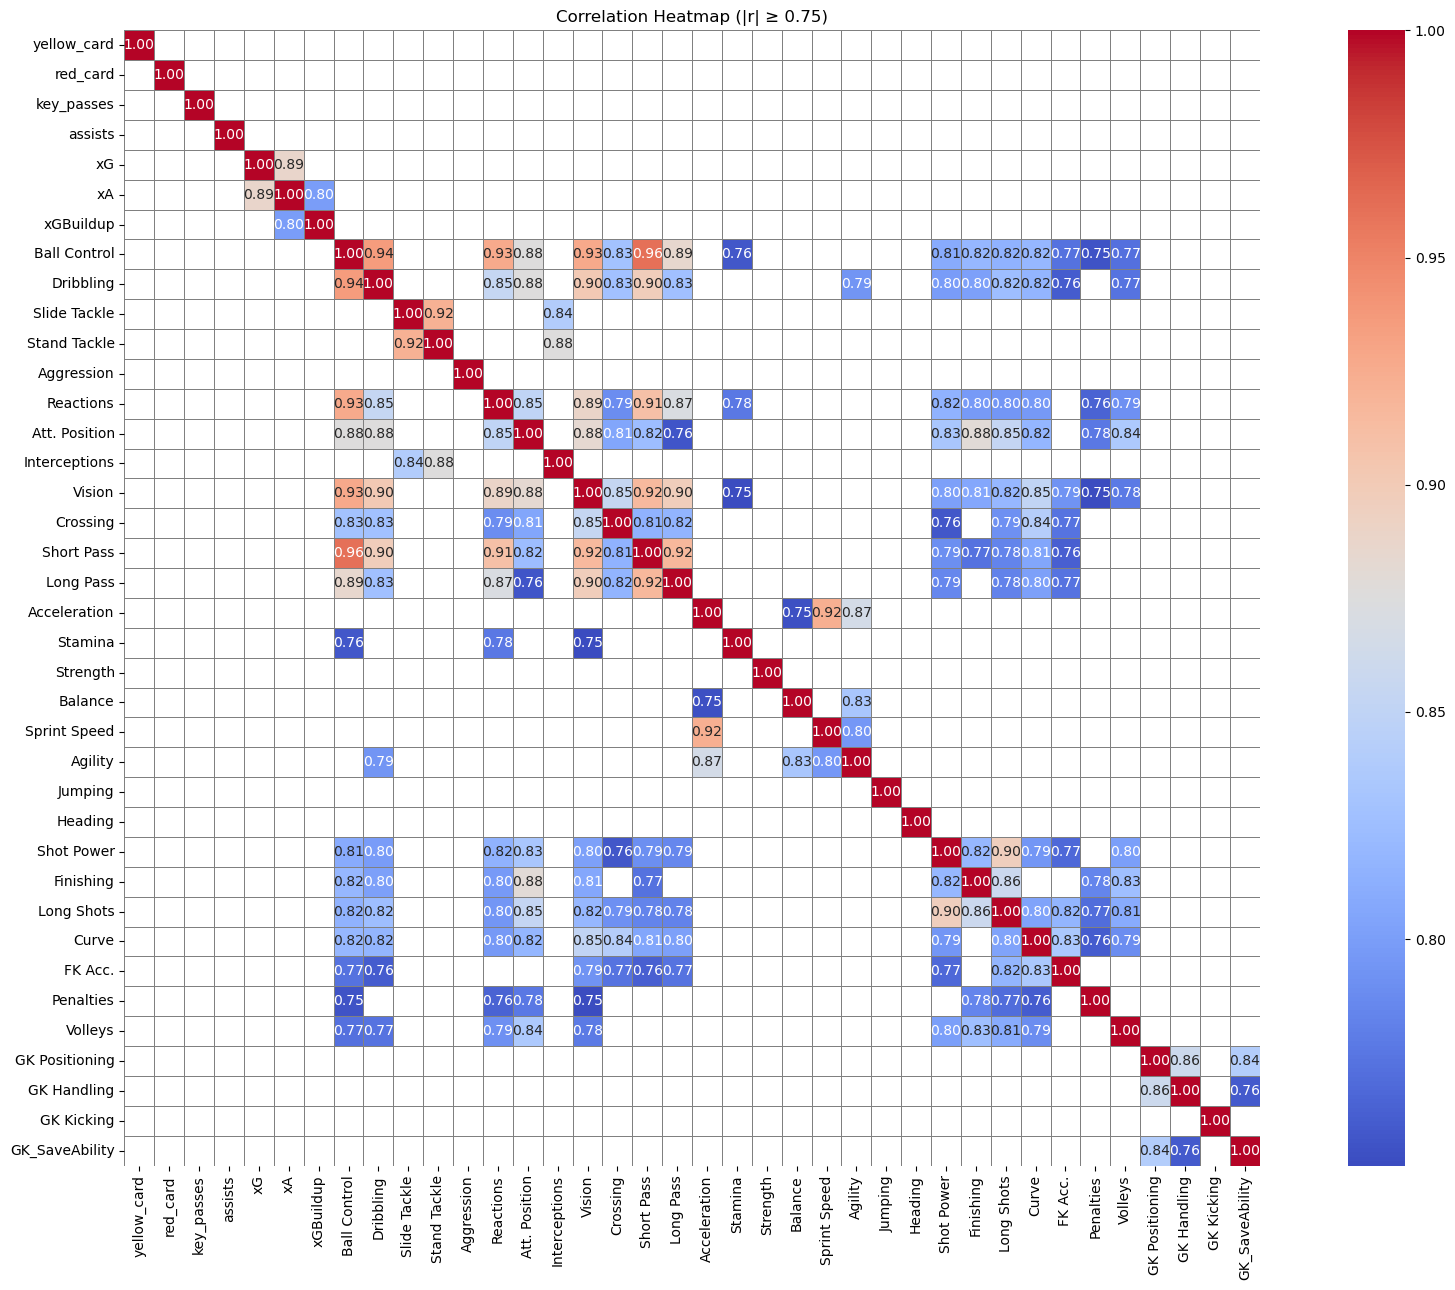

In [1411]:
plot_correlation_matrix(player_stats_df[stat_columns_list])

In [1412]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = player_stats_df[stat_columns_list]
vif = pd.DataFrame()
vif['feature'] = X.columns
vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

In [1413]:
vif.sort_values(by='VIF', ascending=False, inplace=True);vif.reset_index().drop(columns='index')

,feature,VIF
0,Ball Control,29.166256
1,Short Pass,20.655559
2,Dribbling,14.710357
3,Vision,14.388344
4,Reactions,13.622727
5,Acceleration,13.010649
6,Long Pass,11.731411
7,Att. Position,10.956197
8,Sprint Speed,10.814713
9,Stand Tackle,10.625484


In [1414]:
player_stats_df["Overall Ball Skills"]= player_stats_df[["Dribbling", "Ball Control"]].mean(axis=1)
player_stats_df["Overall Passing"]= player_stats_df[["Short Pass", "Long Pass","Crossing"]].mean(axis=1)
player_stats_df["Overall Shooting"]= player_stats_df[["Finishing", "Shot Power", "Long Shots", "Heading", "Curve", "FK Acc.", "Penalties", "Volleys"]].mean(axis=1)
player_stats_df["Overall Defence"]= player_stats_df[["Stand Tackle", "Slide Tackle", "Interceptions"]].mean(axis=1)
player_stats_df["Overall Physical"]= player_stats_df[["Jumping", "Stamina", "Strength", "Acceleration","Agility", "Balance", "Sprint Speed"]].mean(axis=1)
player_stats_df["Overall Goalkeeper"]= player_stats_df[[ "GK Handling", "GK Kicking", "GK Positioning"]].mean(axis=1)
player_stats_df["Overall"]= player_stats_df[["Overall Ball Skills", "Overall Passing", "Overall Shooting", "Overall Defence", "Overall Physical", "Overall Goalkeeper"]].mean(axis=1)

# Now lets normalize the corresponding columns by subtracting the overall stats from the individual stats






In [1415]:
shooting_stats = ["Finishing", "Shot Power", "Long Shots", "Heading", "Curve", "FK Acc.", "Penalties", "Volleys"]
for stat in shooting_stats:
    player_stats_df[f"{stat}_adj"] = player_stats_df[stat] - player_stats_df["Overall Shooting"]
passing_stats = ["Short Pass", "Long Pass", "Crossing"]
for stat in passing_stats:
    player_stats_df[f"{stat}_adj"] = player_stats_df[stat] - player_stats_df["Overall Passing"]

ball_skills_stats = ["Dribbling", "Ball Control"]
for stat in ball_skills_stats:
    player_stats_df[f"{stat}_adj"] = player_stats_df[stat] - player_stats_df["Overall Ball Skills"]

defence_stats = ["Stand Tackle", "Slide Tackle", "Interceptions"]
for stat in defence_stats:
    player_stats_df[f"{stat}_adj"] = player_stats_df[stat] - player_stats_df["Overall Defence"]
physical_stats = ["Jumping", "Stamina", "Strength", "Acceleration", "Agility", "Balance", "Sprint Speed"]
for stat in physical_stats:
    player_stats_df[f"{stat}_adj"] = player_stats_df[stat] - player_stats_df["Overall Physical"]
goalkeeper_stats = ["GK Handling", "GK Kicking", "GK Positioning"]
for stat in goalkeeper_stats:
    player_stats_df[f"{stat}_adj"] = player_stats_df[stat] - player_stats_df["Overall Goalkeeper"]
overall_stats = ["Overall Ball Skills", "Overall Passing", "Overall Shooting", "Overall Defence", "Overall Physical", "Overall Goalkeeper"]
for stat in overall_stats:
    player_stats_df[f"{stat}_adj"] = player_stats_df[stat] - player_stats_df["Overall"]

In [1416]:
columns= shooting_stats + passing_stats + defence_stats + physical_stats + goalkeeper_stats + overall_stats
updated_stats_df = player_stats_df.drop(columns=columns)

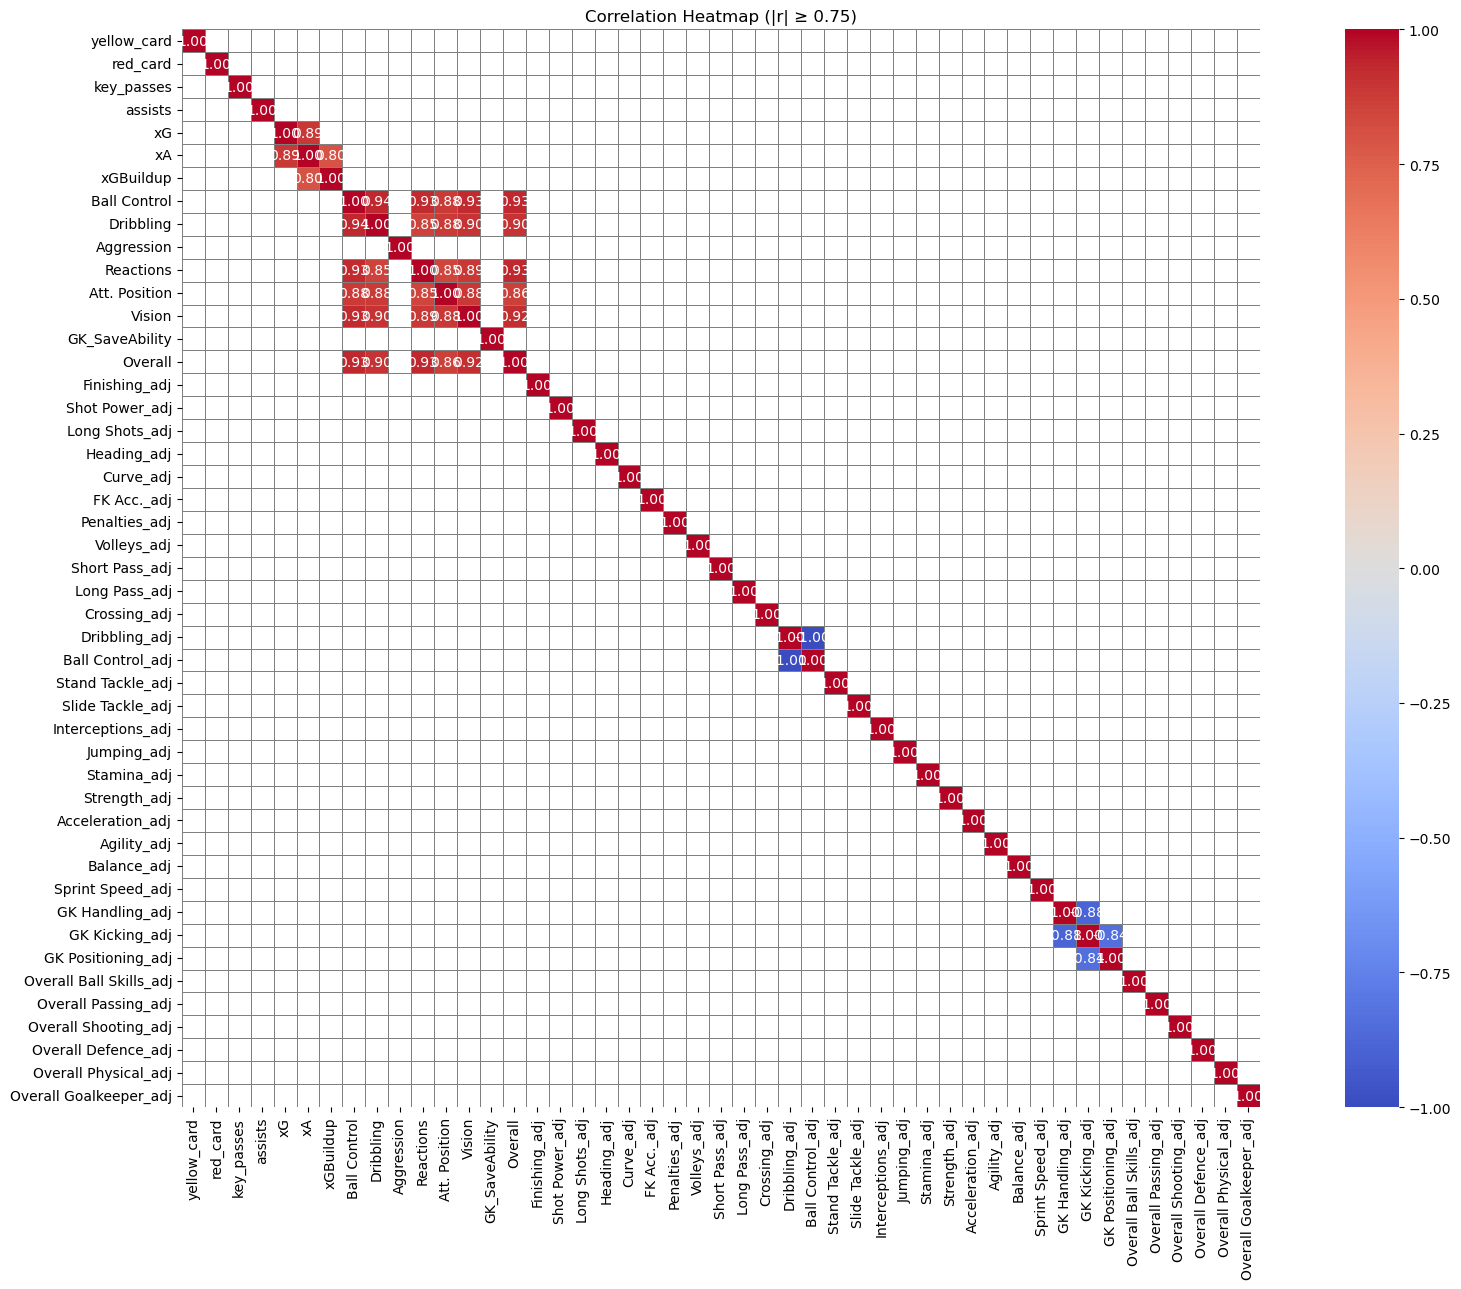

In [1417]:
plot_correlation_matrix(updated_stats_df)

In [ ]:
corr.to_csv('correlation_matrix.csv')

In [ ]:
player_stats_df["Player Name"].nunique()

2883